# Training a Multilayer Perceptron

We classify the sentiment of movie
reviews with a multilayer perceptron (MLP), and we look at everything that happens while the network
learns: the training loop, the learning curves, overfitting, early stopping, and the effect of the
main hyperparameters (optimizer and learning rate, batch size, regularization, width and depth).
We start from the MLP of scikit-learn, then we write the training by hand in PyTorch, and finally we
use skorch, which brings the convenience of scikit-learn back to PyTorch.

The text enters only once, at the beginning: we turn each review into a vector of 300 numbers. From
then on the data is just a matrix.

The corpus is a sample of the **IMDB movie reviews** (Maas et al., 2011): 10,000 reviews to train
and validate on, and 5,000 to test on, half positive and half negative.

In [1]:
# Run once if you are not using the course environment.
# %pip install -q numpy pandas scikit-learn matplotlib torch skorch

In [29]:
import tempfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.dummy import DummyClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, classification_report, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from skorch import NeuralNetBinaryClassifier
from skorch.callbacks import Checkpoint, EarlyStopping, EpochScoring, LRScheduler
from skorch.dataset import Dataset
from skorch.helper import predefined_split

torch.set_num_threads(4)
DEVICE = "cpu"  # the network is small: the CPU is enough

---
## The data

Each review has a label: `1` for positive, `0` for negative. We split the 10,000 labelled reviews
into **8,000 for training** and **2,000 for validation**. The validation set is what we use to take
decisions (which learning rate, when to stop). The **test set is not touched until the very end**.

In [3]:
data = pd.read_csv("Data/imdb_train_10k.csv")
test = pd.read_csv("Data/imdb_test_5k.csv")

clean = lambda s: s.str.replace("<br />", " ", regex=False)  # remove HTML line breaks
train, valid = train_test_split(data, test_size=2000, stratify=data.label, random_state=0)

text_train, y_train = clean(train.text), train.label.values.astype(np.float32)
text_valid, y_valid = clean(valid.text), valid.label.values.astype(np.float32)
text_test, y_test = clean(test.text), test.label.values.astype(np.float32)

print(len(text_train), "training,", len(text_valid), "validation,", len(text_test), "test reviews")
print("share of positive reviews:", y_train.mean().round(3), y_valid.mean().round(3), y_test.mean().round(3))

8000 training, 2000 validation, 5000 test reviews
share of positive reviews: 0.5 0.5 0.5


---
## From text to a dense vector

An MLP needs an input of fixed size, made of numbers. We build it in three steps:

1. **TF-IDF** gives a sparse vector with one coordinate per word (more than 20,000);
2. a truncated **SVD** compresses it into 300 dense coordinates;
3. a **standardization** gives every coordinate mean 0 and standard deviation 1.

Everything is **fitted on the training reviews only**, and then applied to the others.

In [4]:
tfidf = TfidfVectorizer(min_df=3, sublinear_tf=True)
svd = TruncatedSVD(n_components=300, random_state=0)
scaler = StandardScaler()

T_train = tfidf.fit_transform(text_train)
S_train = svd.fit_transform(T_train)
X_train = scaler.fit_transform(S_train).astype(np.float32)

T_valid, T_test = tfidf.transform(text_valid), tfidf.transform(text_test)
X_valid = scaler.transform(svd.transform(T_valid)).astype(np.float32)
X_test = scaler.transform(svd.transform(T_test)).astype(np.float32)

print("TF-IDF:", T_train.shape, "->  dense input:", X_train.shape)

TF-IDF: (8000, 21135) ->  dense input: (8000, 300)


---
## Baselines

Before training a network, what accuracy do simpler models reach on the validation set? We try a
model that always predicts the majority class, and a logistic regression, on the same 300 features
and on the full TF-IDF matrix.

In [5]:
baselines = {
    "always the same class": DummyClassifier(strategy="most_frequent").fit(X_train, y_train).score(X_valid, y_valid),
    "logistic regression, 300 SVD features": LogisticRegression(max_iter=2000).fit(X_train, y_train).score(X_valid, y_valid),
    "logistic regression, full TF-IDF": LogisticRegression(max_iter=2000).fit(T_train, y_train).score(T_valid, y_valid),
}
pd.Series(baselines, name="validation accuracy").round(3).to_frame()

,validation accuracy
always the same class,0.500
"logistic regression, 300 SVD features",0.872
"logistic regression, full TF-IDF",0.886


---
## A first MLP, with scikit-learn

The easiest way to train an MLP is `MLPClassifier`: one hidden layer with 64 neurons, the Adam
optimizer, and the usual `fit` and `score`. The loss it minimizes is the cross-entropy, and it
keeps the training loss of every epoch in `loss_curve_`.

epochs: 77
validation accuracy: 0.865


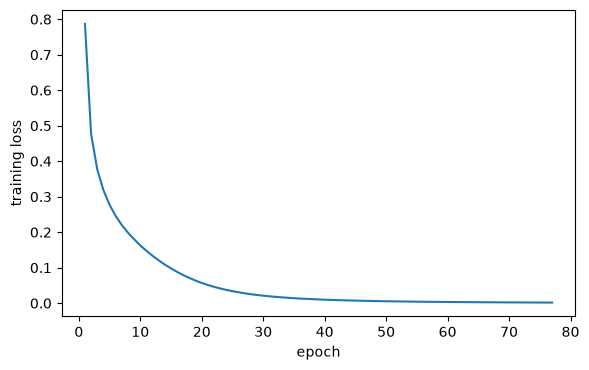

In [6]:
mlp_sk = MLPClassifier(hidden_layer_sizes=(64,), solver="adam", max_iter=200, random_state=0)
mlp_sk.fit(X_train, y_train)

print("epochs:", mlp_sk.n_iter_)
print("validation accuracy:", round(mlp_sk.score(X_valid, y_valid), 3))

plt.figure(figsize=(6, 3.8))
plt.plot(np.arange(1, len(mlp_sk.loss_curve_) + 1), mlp_sk.loss_curve_)
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.tight_layout()
plt.show()

It works in a few lines, and the validation accuracy (about 0.87) is already close to the logistic
regression. But look at what we cannot see:

- the only curve is the **training loss**, which keeps going down. Training stops when that loss stops improving, and this says nothing about how the network behaves on new reviews;
-  can stop on a validation score, but it is the accuracy, and the validation loss is not recorded;
- there is no dropout, no learning rate scheduler, and no choice of the loss.

To see what happens during the training, we write it ourselves.

---
## A first MLP, with a hand-written training loop

The network has one hidden layer with 64 neurons and a ReLU. Its output is **one number**, the
*logit* of the positive class: the probability would be its sigmoid. The loss is the binary
cross-entropy, `BCEWithLogitsLoss`, which applies the sigmoid inside (it is more numerically stable
than computing the sigmoid ourselves). A review is predicted positive when the logit is above zero.

In [7]:
model = nn.Sequential(
    nn.Linear(300, 64),  # 300 input features, 64 hidden neurons
    nn.ReLU(),
    nn.Linear(64, 1),  # one output: the logit of the positive class
)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=300, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=1, bias=True)
)
trainable parameters: 19329


Training means repeating three steps over **mini-batches**: compute the loss, compute the gradients
with backpropagation, and let the optimizer update the weights. One pass over all the training
reviews is an **epoch**. After every epoch we measure loss and accuracy on the training and on the
validation set, so that we can draw the **learning curves**.

In [8]:
# in torch, the data is represented as tensors, which are similar to numpy arrays but can be used on GPUs and support automatic differentiation
Xt, yt = torch.tensor(X_train), torch.tensor(y_train).unsqueeze(1)  # unsqueeze y to make it a column vector
Xv, yv = torch.tensor(X_valid), torch.tensor(y_valid).unsqueeze(1)

In [9]:
# we define an evaluation function that computes the loss and accuracy on a given dataset

def evaluate(model, X, y):
    model.eval()  # set the model to evaluation mode
    with torch.no_grad():  # no gradients needed for evaluation
        logits = model(X)
        loss = loss_fn(logits, y).item()  # loss_fn is defined later in the code
        acc = ((logits > 0).float() == y).float().mean().item()
    return loss, acc

In [10]:
torch.manual_seed(0)

loss_fn = nn.BCEWithLogitsLoss()  # binary cross-entropy loss with logits, suitable for binary classification tasks
model = nn.Sequential(nn.Linear(300, 64), nn.ReLU(), nn.Linear(64, 1))  # sequential means the layers are applied in order
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = DataLoader(TensorDataset(Xt, yt), batch_size=64, shuffle=True)  # we wrap the training data in a DataLoader to iterate over it in batches

# training loop
history = []
for epoch in range(30):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()  # forget the gradients of the previous batch
        loss = loss_fn(model(xb), yb)  # forward pass
        loss.backward()  # backward pass (compute gradients)
        optimizer.step()  # update the weights
    tl, ta = evaluate(model, Xt, yt)
    vl, va = evaluate(model, Xv, yv)
    history.append(dict(train_loss=tl, valid_loss=vl, train_acc=ta, valid_acc=va))

history = pd.DataFrame(history)
history.round(3).iloc[[0, 1, 2, 4, 9, 19, 29]]

,train_loss,valid_loss,train_acc,valid_acc
0,0.361,0.401,0.891,0.861
1,0.236,0.312,0.914,0.872
2,0.195,0.303,0.933,0.870
4,0.136,0.311,0.962,0.872
9,0.040,0.359,0.997,0.868
19,0.005,0.461,1.000,0.867
29,0.002,0.538,1.000,0.865


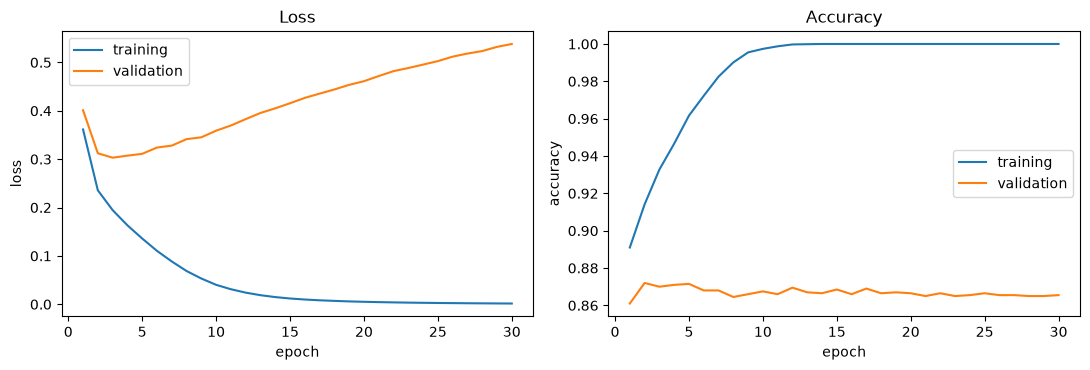

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(history.index + 1, history.train_loss, label="training")
axes[0].plot(history.index + 1, history.valid_loss, label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(history.index + 1, history.train_acc, label="training")
axes[1].plot(history.index + 1, history.valid_acc, label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Reading the curves:

- the **training loss** keeps falling and the training accuracy reaches 100%: the network memorizes the training reviews;
- the **validation loss** falls for the first few epochs, reaches a minimum (around the third epoch), and then **rises**: the network becomes more and more confident on the reviews it has seen, and confidently wrong on new ones. This is **overfitting**;
- the **validation accuracy** barely moves (about 0.87). The accuracy only counts right and wrong decisions, while the loss also measures how confident they are, so the loss is the better signal to watch.

---
## The same training, with skorch

Every idea we add (a learning rate scheduler, another metric, saving the best model, trying a
different optimizer) means more bookkeeping inside the loop. **skorch** wraps a PyTorch module in a
scikit-learn style object: `fit`, `predict`, `score`, and the loop, the validation, the history and the
**callbacks** (early stopping, learning rate scheduling, checkpoints) are already there.

skorch needs the network as a **class** that it can build again with different options, so we write the
same network as before as a module, with the number of neurons and the dropout as arguments (with
`dropout=0.0` it is exactly the network we trained by hand). We give skorch the validation set, so that it computes the
validation loss and accuracy at every epoch.


In [12]:
class MLP(nn.Module):
    def __init__(self, in_features, hidden=(64,), dropout=0.0):
        super().__init__()
        layers, d = [], in_features
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))  # one output: the logit of the positive class
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)  # shape (batch,)

The same network as before, now with skorch. With `verbose=1` it prints a table with one row per
epoch: training loss, validation accuracy, validation loss, and the time.

In [13]:
valid_ds = Dataset(X_valid, y_valid)  # skorch computes the validation loss and accuracy on this set

torch.manual_seed(0)
net = NeuralNetBinaryClassifier(
    MLP,
    module__in_features=X_train.shape[1],  # the arguments of the module have the prefix module__
    optimizer=torch.optim.Adam,
    lr=1e-3,
    batch_size=64,
    max_epochs=8,
    train_split=predefined_split(valid_ds),
    device=DEVICE,
    verbose=1,  # prints one row per epoch
    callbacks=[
        EpochScoring(
            scoring="accuracy",
            name="train_acc",
            on_train=True,
            lower_is_better=False,
        ),
    ],
)
net.fit(X_train, y_train)

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.7499        0.5627       0.8590        0.3997  0.0875
      2       0.8814        0.3114       0.8695        0.3144  0.0844
      3       0.9045        0.2452       0.8675        0.3081  0.0866
      4       0.9230        0.2088       0.8680        0.3103  0.0861
      5       0.9369        0.1776       0.8675        0.3153  0.0865
      6       0.9533        0.1480       0.8660        0.3223  0.0853
      7       0.9664        0.1205       0.8630        0.3305  0.0844
      8       0.9786        0.0954       0.8640        0.3391  0.0870


,module,<class '__main__.MLP'>
,criterion,<class 'torch...thLogitsLoss'>
,train_split,functools.par... 0x30d8a3d70>)
,threshold,0.5
,optimizer,<class 'torch...im.adam.Adam'>
,lr,0.001
,max_epochs,8
,batch_size,64
,iterator_train,<class 'torch...r.DataLoader'>
,iterator_valid,<class 'torch...r.DataLoader'>
,dataset,<class 'skorc...aset.Dataset'>


The training loss that skorch prints is the average over the batches **during** the epoch, while the
weights are still changing, so in the first epochs it is higher than the one we computed after the
epoch. The accuracy on the training set is not computed by default: we added it with the `EpochScoring` callback and `on_train=True`. The history of the run is in `net.history`, and we can plot it as we did before. In the next sections we compare many runs, always on the validation set.

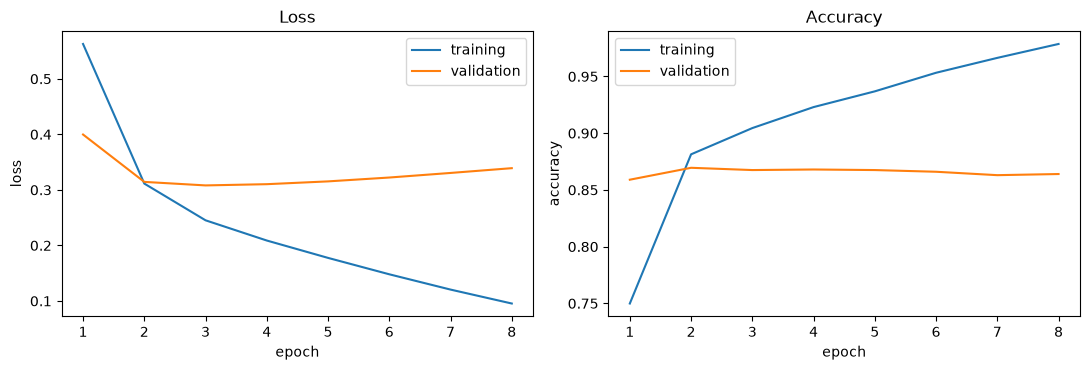

In [14]:
h = net.history
epochs = np.arange(1, len(h) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, h[:, "train_loss"], label="training")
axes[0].plot(epochs, h[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, h[:, "train_acc"], label="training")
axes[1].plot(epochs, h[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Optimizer and learning rate

The learning rate is usually the **most important hyperparameter**. Too small and the network learns
slowly; too large and it oscillates or diverges. Plain SGD and Adam also need very different values.
We train 30 epochs for every setting, with no early stopping, to see the whole curve.

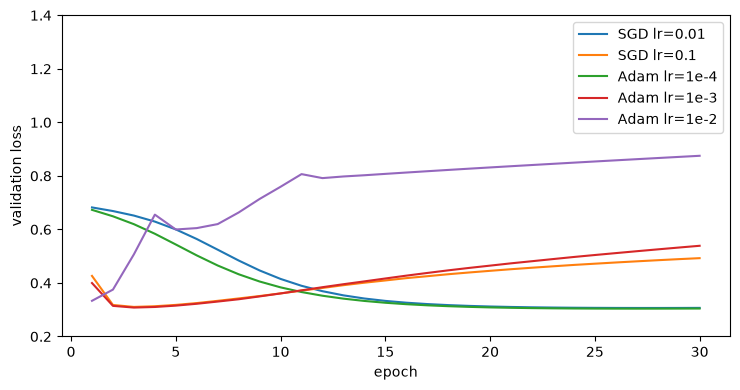

,best_valid_loss,best_epoch,last_valid_loss,last_valid_acc,seconds,epochs
SGD lr=0.01,0.307,28.0,0.307,0.872,2.403,30.0
SGD lr=0.1,0.311,3.0,0.493,0.857,2.114,30.0
Adam lr=1e-4,0.304,27.0,0.304,0.874,2.638,30.0
Adam lr=1e-3,0.308,3.0,0.539,0.863,2.792,30.0
Adam lr=1e-2,0.333,1.0,0.875,0.857,2.660,30.0


In [16]:
configs = {
    "SGD lr=0.01": dict(optimizer=torch.optim.SGD, lr=0.01),
    "SGD lr=0.1": dict(optimizer=torch.optim.SGD, lr=0.1),
    "Adam lr=1e-4": dict(lr=1e-4),
    "Adam lr=1e-3": dict(lr=1e-3),
    "Adam lr=1e-2": dict(lr=1e-2),
}

rows = {}

plt.figure(figsize=(7.5, 4))
for name, params in configs.items():
    torch.manual_seed(0)
    net = NeuralNetBinaryClassifier(
        MLP,
        module__in_features=X_train.shape[1],
        optimizer=torch.optim.Adam,
        lr=1e-3,
        batch_size=64,
        max_epochs=30,
        train_split=predefined_split(valid_ds),
        device=DEVICE,
        verbose=0,
    )
    net.set_params(**params)
    t0 = time.time()
    net.fit(X_train, y_train)
    seconds = time.time() - t0

    valid_loss = net.history[:, "valid_loss"]
    rows[name] = dict(
        best_valid_loss=min(valid_loss),
        best_epoch=int(np.argmin(valid_loss)) + 1,
        last_valid_loss=valid_loss[-1],
        last_valid_acc=net.history[-1, "valid_acc"],
        seconds=seconds,
        epochs=len(valid_loss),
    )
    plt.plot(np.arange(1, len(valid_loss) + 1), valid_loss, label=name)

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.ylim(0.2, 1.4)
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows).T.round(3)

- The lowest validation loss is **about the same** for all the settings (around 0.30 to 0.31). It is a limit of the features and of the model, not of the optimizer.
- What changes is **how fast** we reach it, and how fast the network overfits afterwards. SGD with 0.01 and Adam with 1e-4 are slow and are still improving after 30 epochs. Adam with 1e-3 and SGD with 0.1 reach the minimum in about three epochs and then overfit. Adam with 1e-2 is too aggressive: its best loss is higher, and it overfits from the first epoch.
- SGD and Adam need learning rates that differ by orders of magnitude: a value that is good for one can be bad for the other.

---
## Batch size

The batch size decides how many reviews are used for every update of the weights. Small batches give
many noisy updates per epoch, large batches give few and smoother ones.

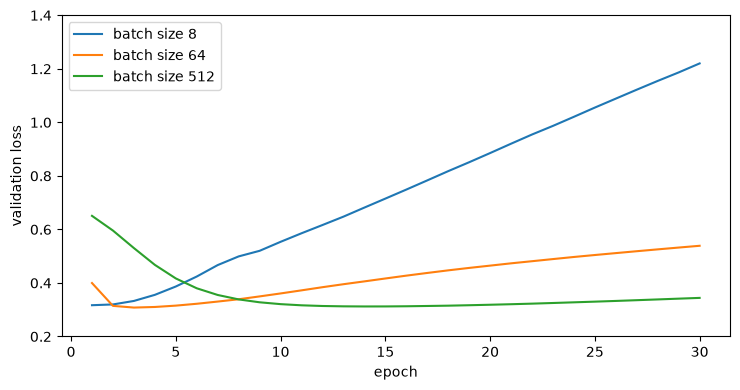

,best_valid_loss,best_epoch,last_valid_loss,last_valid_acc,seconds,epochs
batch size 8,0.317,1.0,1.220,0.868,15.561,30.0
batch size 64,0.308,3.0,0.539,0.863,2.781,30.0
batch size 512,0.312,14.0,0.344,0.870,1.142,30.0


In [17]:
configs = {
    "batch size 8": dict(batch_size=8),
    "batch size 64": dict(batch_size=64),
    "batch size 512": dict(batch_size=512),
}

rows = {}

plt.figure(figsize=(7.5, 4))
for name, params in configs.items():
    torch.manual_seed(0)
    net = NeuralNetBinaryClassifier(
        MLP,
        module__in_features=X_train.shape[1],
        optimizer=torch.optim.Adam,
        lr=1e-3,
        batch_size=64,
        max_epochs=30,
        train_split=predefined_split(valid_ds),
        device=DEVICE,
        verbose=0,
    )
    net.set_params(**params)
    t0 = time.time()
    net.fit(X_train, y_train)
    seconds = time.time() - t0

    valid_loss = net.history[:, "valid_loss"]
    rows[name] = dict(
        best_valid_loss=min(valid_loss),
        best_epoch=int(np.argmin(valid_loss)) + 1,
        last_valid_loss=valid_loss[-1],
        last_valid_acc=net.history[-1, "valid_acc"],
        seconds=seconds,
        epochs=len(valid_loss),
    )
    plt.plot(np.arange(1, len(valid_loss) + 1), valid_loss, label=name)

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.ylim(0.2, 1.4)
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows).T.round(3)

- With **8** reviews per batch there are 1,000 updates per epoch: the network overfits already in the first epoch, and an epoch is much slower (about 13 s, against 2 s with 64).
- With **512** there are only 16 updates per epoch: the network needs more epochs (its best is around the fourteenth), it overfits slowly, and every epoch is fast.
- The best validation loss is again similar. The batch size changes the speed, in time and in epochs, and the noise of the updates.

---
## Regularization

The curves above show **overfitting**: the network memorizes the training reviews. Two common
remedies are **dropout**, which switches off a random fraction of the hidden neurons at every step, and
**weight decay**, which penalizes large weights.

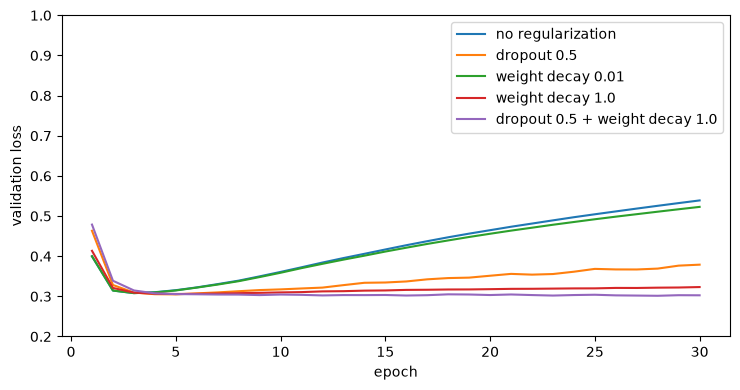

,best_valid_loss,best_epoch,last_valid_loss,last_valid_acc,seconds,epochs
no regularization,0.308,3.0,0.539,0.863,2.776,30.0
dropout 0.5,0.305,5.0,0.379,0.866,2.693,30.0
weight decay 0.01,0.308,3.0,0.523,0.865,2.572,30.0
weight decay 1.0,0.306,5.0,0.323,0.868,2.712,30.0
dropout 0.5 + weight decay 1.0,0.301,28.0,0.303,0.872,2.763,30.0


In [18]:
configs = {
    "no regularization": dict(),
    "dropout 0.5": dict(module__dropout=0.5),
    "weight decay 0.01": dict(optimizer=torch.optim.AdamW, optimizer__weight_decay=0.01),
    "weight decay 1.0": dict(optimizer=torch.optim.AdamW, optimizer__weight_decay=1.0),
    "dropout 0.5 + weight decay 1.0": dict(module__dropout=0.5, optimizer=torch.optim.AdamW,
                                           optimizer__weight_decay=1.0),
}

rows = {}

plt.figure(figsize=(7.5, 4))
for name, params in configs.items():
    torch.manual_seed(0)
    net = NeuralNetBinaryClassifier(
        MLP,
        module__in_features=X_train.shape[1],
        optimizer=torch.optim.Adam,
        lr=1e-3,
        batch_size=64,
        max_epochs=30,
        train_split=predefined_split(valid_ds),
        device=DEVICE,
        verbose=0,
    )
    net.set_params(**params)
    t0 = time.time()
    net.fit(X_train, y_train)
    seconds = time.time() - t0

    valid_loss = net.history[:, "valid_loss"]
    rows[name] = dict(
        best_valid_loss=min(valid_loss),
        best_epoch=int(np.argmin(valid_loss)) + 1,
        last_valid_loss=valid_loss[-1],
        last_valid_acc=net.history[-1, "valid_acc"],
        seconds=seconds,
        epochs=len(valid_loss),
    )
    plt.plot(np.arange(1, len(valid_loss) + 1), valid_loss, label=name)

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.ylim(0.2, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows).T.round(3)

- **Dropout 0.5** does not lower the best validation loss much (about 0.305), but the network overfits much more slowly: at epoch 30 the validation loss is 0.38, against 0.54 without regularization.
- **Weight decay** with 0.01, a common default, does almost nothing here, while with 1.0 it works. AdamW multiplies the decay by the learning rate, so 0.01 shrinks the weights by only 1e-5 at every step. The right value depends on the optimizer, and it must be tuned.
- **Together**, the validation loss does not rise within 30 epochs. Regularization does not give a much better model: it gives a **more patient training**, in which the exact stopping epoch matters less.

---
## Width and depth

A wider network has more neurons in a layer, a deeper one has more layers. Both increase the
capacity, that is, the ability to fit the training data (including its noise).

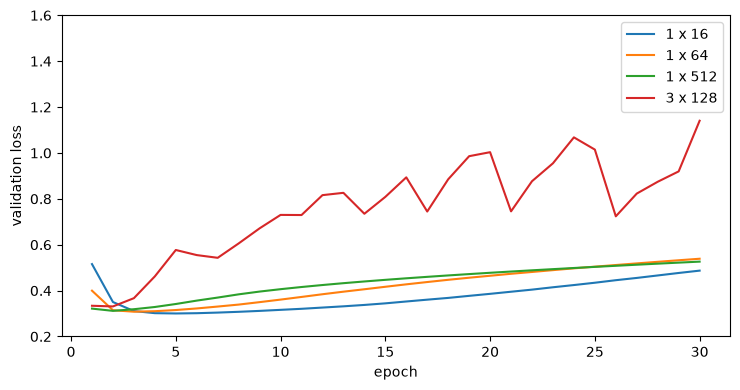

,best_valid_loss,best_epoch,last_valid_loss,last_valid_acc,seconds,epochs,parameters
1 x 16,0.300,5.0,0.487,0.859,2.598,30.0,4833.0
1 x 64,0.308,3.0,0.539,0.863,2.752,30.0,19329.0
1 x 512,0.312,2.0,0.526,0.870,5.502,30.0,154625.0
3 x 128,0.331,2.0,1.140,0.854,4.871,30.0,71681.0


In [19]:
configs = {
    "1 x 16": dict(module__hidden=(16,)),
    "1 x 64": dict(module__hidden=(64,)),
    "1 x 512": dict(module__hidden=(512,)),
    "3 x 128": dict(module__hidden=(128, 128, 128)),
}

rows = {}

plt.figure(figsize=(7.5, 4))
for name, params in configs.items():
    torch.manual_seed(0)
    net = NeuralNetBinaryClassifier(
        MLP,
        module__in_features=X_train.shape[1],
        optimizer=torch.optim.Adam,
        lr=1e-3,
        batch_size=64,
        max_epochs=30,
        train_split=predefined_split(valid_ds),
        device=DEVICE,
        verbose=0,
    )
    net.set_params(**params)
    t0 = time.time()
    net.fit(X_train, y_train)
    seconds = time.time() - t0

    valid_loss = net.history[:, "valid_loss"]
    rows[name] = dict(
        best_valid_loss=min(valid_loss),
        best_epoch=int(np.argmin(valid_loss)) + 1,
        last_valid_loss=valid_loss[-1],
        last_valid_acc=net.history[-1, "valid_acc"],
        seconds=seconds,
        epochs=len(valid_loss),
        parameters=sum(p.numel() for p in net.module_.parameters()),
    )
    plt.plot(np.arange(1, len(valid_loss) + 1), valid_loss, label=name)

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.ylim(0.2, 1.6)
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows).T.round(3)

- The **narrow** network (16 neurons, 4,800 parameters) reaches the lowest validation loss (about 0.30): this problem does not need more capacity.
- The **wide** one (512 neurons) and the **deep** one (3 layers of 128) do not do better. They reach their best loss earlier and overfit faster, and the deep one has the worst best loss (0.33).
- More parameters also mean more time: twice as long per epoch for the wide and the deep network. A larger network does not make a better model when the information in the input is limited.

---
## Every run is different

The initial weights and the order of the mini-batches are random. We train the same network with
five seeds.

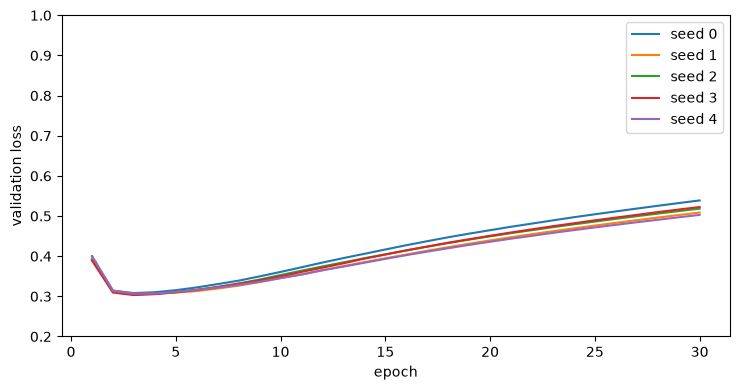

best validation loss: 0.303 to 0.308
validation accuracy at epoch 30: 0.862 to 0.875


In [20]:
configs = {f"seed {seed}": dict() for seed in range(5)}

rows = {}

plt.figure(figsize=(7.5, 4))
for name, params in configs.items():
    torch.manual_seed(int(name.split()[1]))
    net = NeuralNetBinaryClassifier(
        MLP,
        module__in_features=X_train.shape[1],
        optimizer=torch.optim.Adam,
        lr=1e-3,
        batch_size=64,
        max_epochs=30,
        train_split=predefined_split(valid_ds),
        device=DEVICE,
        verbose=0,
    )
    net.set_params(**params)
    t0 = time.time()
    net.fit(X_train, y_train)
    seconds = time.time() - t0

    valid_loss = net.history[:, "valid_loss"]
    rows[name] = dict(
        best_valid_loss=min(valid_loss),
        best_epoch=int(np.argmin(valid_loss)) + 1,
        last_valid_loss=valid_loss[-1],
        last_valid_acc=net.history[-1, "valid_acc"],
        seconds=seconds,
        epochs=len(valid_loss),
    )
    plt.plot(np.arange(1, len(valid_loss) + 1), valid_loss, label=name)

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.ylim(0.2, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

table = pd.DataFrame(rows).T.round(3)
print("best validation loss:", table.best_valid_loss.min(), "to", table.best_valid_loss.max())
print("validation accuracy at epoch 30:", table.last_valid_acc.min(), "to", table.last_valid_acc.max())

With the same configuration, the best validation loss moves between 0.303 and 0.308, and the validation accuracy between 0.862 and 0.875, a spread of more than one point. The validation set has only 2,000 reviews, so the accuracy has a standard error of about 0.75 points on its own.

A single run is not enough to say that one setting beats another: **a difference of a point of accuracy is inside the noise**. To compare settings we need several seeds, or a larger validation set.

---
## Putting it together

We combine what we learned: Adam with a moderate learning rate, dropout and weight decay, a
**learning rate scheduler** that halves the learning rate when the validation loss stops improving,
**early stopping**, and a **checkpoint** that restores the weights of the best epoch.

In [22]:
checkpoint_dir = tempfile.mkdtemp()  # where skorch saves the best weights

torch.manual_seed(0)
final = NeuralNetBinaryClassifier(
    MLP,
    module__in_features=X_train.shape[1],
    module__dropout=0.5,
    optimizer=torch.optim.AdamW,
    optimizer__weight_decay=1.0,
    lr=1e-3,
    batch_size=64,
    max_epochs=100,
    train_split=predefined_split(valid_ds),
    device=DEVICE,
    verbose=1,
    callbacks=[
        EpochScoring(
            scoring="accuracy",
            name="train_acc",
            on_train=True,
            lower_is_better=False,
        ),
        LRScheduler(policy="ReduceLROnPlateau", monitor="valid_loss", factor=0.5, patience=2),
        EarlyStopping(monitor="valid_loss", patience=6),
        Checkpoint(monitor="valid_loss_best", dirname=checkpoint_dir, load_best=True, f_history=None),
    ],
)
final.fit(X_train, y_train)

  epoch    train_acc    train_loss    valid_acc    valid_loss    cp      lr     dur
-------  -----------  ------------  -----------  ------------  ----  ------  ------
      1       0.7023        0.6098       0.8600        0.4787     +  0.0010  0.1219
      2       0.8598        0.3879       0.8715        0.3388     +  0.0010  0.1012
      3       0.8814        0.3072       0.8685        0.3147     +  0.0010  0.1012
      4       0.8898        0.2834       0.8735        0.3074     +  0.0010  0.0948
      5       0.8949        0.2723       0.8725        0.3056     +  0.0010  0.1410
      6       0.8986        0.2636       0.8720        0.3051     +  0.0010  0.1360
      7       0.8992        0.2589       0.8710        0.3045     +  0.0010  0.1608
      8       0.9036        0.2517       0.8700        0.3044     +  0.0010  0.0988
      9       0.9097        0.2494       0.8735        0.3031     +  0.0010  0.0988
     10       0.9076        0.2455       0.8690        0.3045        0.0010 

,module,<class '__main__.MLP'>
,criterion,<class 'torch...thLogitsLoss'>
,train_split,functools.par... 0x30d8a3d70>)
,threshold,0.5
,optimizer,<class 'torch....adamw.AdamW'>
,lr,0.001
,max_epochs,100
,batch_size,64
,iterator_train,<class 'torch...r.DataLoader'>
,iterator_valid,<class 'torch...r.DataLoader'>
,dataset,<class 'skorc...aset.Dataset'>


stopped after 23 epochs, best epoch: 17


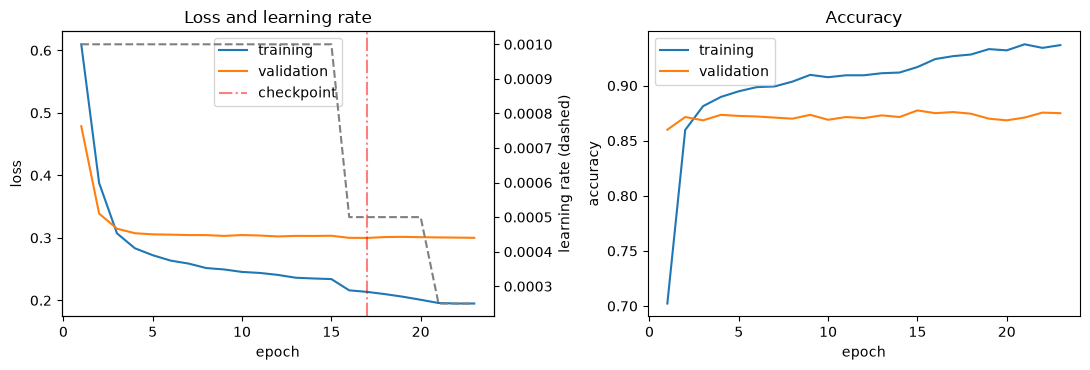

In [23]:
h = final.history
epochs = np.arange(1, len(h) + 1)
best_epoch = [i for i, saved in enumerate(h[:, "event_cp"]) if saved][-1] + 1  # the last epoch in which a checkpoint was saved
print(f"stopped after {len(h)} epochs, best epoch: {best_epoch}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, h[:, "train_loss"], label="training")
axes[0].plot(epochs, h[:, "valid_loss"], label="validation")
axes[0].axvline(best_epoch, color="red", linestyle="-.", alpha=0.5, label="checkpoint")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss and learning rate")
axes[0].legend()
lr_axis = axes[0].twinx()  # a second y-axis, for the learning rate
lr_axis.plot(epochs, h[:, "event_lr"], color="gray", linestyle="--")
lr_axis.set_ylabel("learning rate (dashed)")

axes[1].plot(epochs, h[:, "train_acc"], label="training")
axes[1].plot(epochs, h[:, "valid_acc"], label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

The scheduler halves the learning rate when the validation loss stops improving (dashed line), early stopping ends the training after a few tens of epochs, and the checkpoint (red line) marks the epoch whose weights are restored. We did not write a line of the loop.

---
## The test set

Only now we use the test reviews, once, for the final model and for the logistic regressions.

In [24]:
lr_svd = LogisticRegression(max_iter=2000).fit(X_train, y_train)
lr_tfidf = LogisticRegression(max_iter=2000).fit(T_train, y_train)

test_scores = {
    "logistic regression, 300 SVD features": lr_svd.score(X_test, y_test),
    "logistic regression, full TF-IDF": lr_tfidf.score(T_test, y_test),
    "MLP, early stopping": (final.predict(X_test) == y_test).mean(),
}
print(pd.Series(test_scores, name="test accuracy").round(3).to_string())
print()
print(classification_report(y_test, final.predict(X_test), target_names=["negative", "positive"], digits=3))

logistic regression, 300 SVD features    0.871
logistic regression, full TF-IDF         0.869
MLP, early stopping                      0.874

              precision    recall  f1-score   support

    negative      0.868     0.882     0.875      2500
    positive      0.880     0.866     0.873      2500

    accuracy                          0.874      5000
   macro avg      0.874     0.874     0.874      5000
weighted avg      0.874     0.874     0.874      5000



Accuracy and the report depend on a threshold (a review is positive if its probability is above 0.5).
The confusion matrix shows where the errors are. The ROC curve and the precision-recall curve use the
**probabilities** instead, and compare the MLP with the logistic regression on the same features.

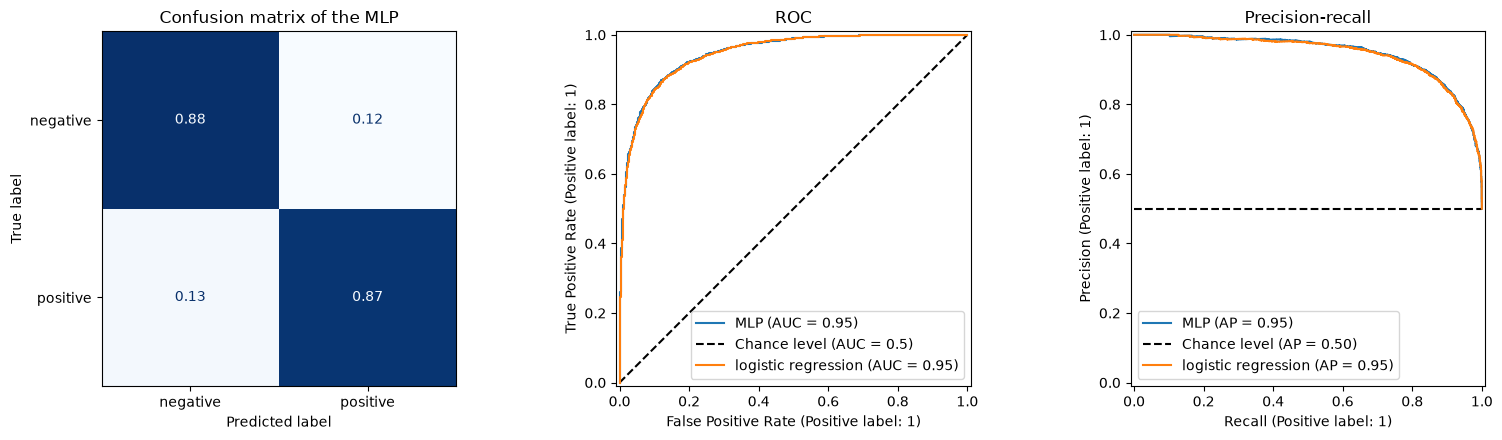

ROC-AUC: 0.947 (MLP), 0.946 (logistic regression)
average precision: 0.947 (MLP), 0.946 (logistic regression)


In [25]:
proba_mlp = final.predict_proba(X_test)[:, 1]
proba_lr = lr_svd.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, final.predict(X_test), display_labels=["negative", "positive"],
                                        normalize="true", values_format=".2f", cmap="Blues",
                                        colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix of the MLP")

RocCurveDisplay.from_predictions(y_test, proba_mlp, name="MLP", ax=axes[1], plot_chance_level=True)
RocCurveDisplay.from_predictions(y_test, proba_lr, name="logistic regression", ax=axes[1])
axes[1].set_title("ROC")

PrecisionRecallDisplay.from_predictions(y_test, proba_mlp, name="MLP", ax=axes[2], plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, name="logistic regression", ax=axes[2])
axes[2].set_title("Precision-recall")

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc_score(y_test, proba_mlp), 3), "(MLP),", round(roc_auc_score(y_test, proba_lr), 3), "(logistic regression)")
print("average precision:", round(average_precision_score(y_test, proba_mlp), 3), "(MLP),", round(average_precision_score(y_test, proba_lr), 3), "(logistic regression)")

The three models are **equivalent**: about 0.87, within the noise (with 5,000 test reviews, one standard error is about half a point). The confusion matrix shows errors of similar size on the two classes (12% and 13%), and the ROC and precision-recall curves of the MLP and of the logistic regression almost overlap, with the same area (0.95). The MLP is not better than a logistic regression on the same features.

The reason is the input, not the training. After TF-IDF and SVD there is little nonlinear structure left for the hidden layer, and a linear model on a few hundred dense features is already good. The techniques of this notebook do not make a network better than its data allows: they let it **reach its best without wasting it**, with a stopping rule, a sensible learning rate and some regularization.

---
## Monitoring another metric

The loss is what the network minimizes, but it is not always what we want to report. skorch can compute
any scikit-learn metric at every epoch with `EpochScoring`, and the other callbacks can use it: the
scheduler, early stopping and the checkpoint only need the **name** of the quantity and its **direction**.
Here we monitor the F1 of the positive class, for which higher is better: `lower_is_better=False`, and
`mode="max"` for the scheduler.

  epoch    train_f1    train_loss    valid_acc    valid_f1    valid_loss    cp      lr     dur
-------  ----------  ------------  -----------  ----------  ------------  ----  ------  ------
      1      0.6904        0.6098       0.8600      0.8601        0.4787     +  0.0010  0.1216
      2      0.8611        0.3879       0.8715      0.8714        0.3388     +  0.0010  0.0946
      3      0.8826        0.3072       0.8685      0.8682        0.3147        0.0010  0.0993
      4      0.8908        0.2834       0.8735      0.8729        0.3074     +  0.0010  0.0926
      5      0.8954        0.2723       0.8725      0.8727        0.3056        0.0010  0.1036
      6      0.8993        0.2636       0.8720      0.8717        0.3051        0.0010  0.0968
      7      0.8999        0.2589       0.8710      0.8709        0.3045        0.0010  0.1207
      8      0.9105        0.2407       0.8720      0.8725        0.3029        0.0005  0.1126
      9      0.9201        0.2365       0.8730    

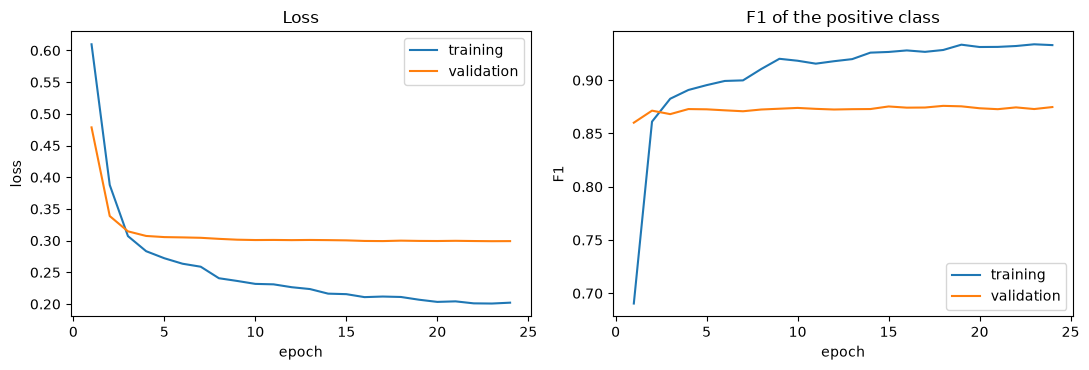

In [27]:
checkpoint_dir_f1 = tempfile.mkdtemp()  # a separate folder for this model

torch.manual_seed(0)
net_f1 = NeuralNetBinaryClassifier(
    MLP,
    module__in_features=X_train.shape[1],
    module__dropout=0.5,
    optimizer=torch.optim.AdamW,
    optimizer__weight_decay=1.0,
    lr=1e-3,
    batch_size=64,
    max_epochs=100,
    train_split=predefined_split(valid_ds),
    device=DEVICE,
    verbose=1,
    callbacks=[
        EpochScoring(
            scoring="f1",
            name="train_f1",
            on_train=True,
            lower_is_better=False,
        ),
        EpochScoring(
            scoring="f1",
            name="valid_f1",
            on_train=False,
            lower_is_better=False,
        ),
        LRScheduler(policy="ReduceLROnPlateau", monitor="valid_f1", mode="max", factor=0.5, patience=2),
        EarlyStopping(monitor="valid_f1", patience=6, lower_is_better=False),
        Checkpoint(monitor="valid_f1_best", dirname=checkpoint_dir_f1, load_best=True, f_history=None),
    ],
)
net_f1.fit(X_train, y_train)

h = net_f1.history
epochs = np.arange(1, len(h) + 1)
print(f"stopped after {len(h)} epochs, best epoch by validation F1: {int(np.argmax(h[:, 'valid_f1'])) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(epochs, h[:, "train_loss"], label="training")
axes[0].plot(epochs, h[:, "valid_loss"], label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(epochs, h[:, "train_f1"], label="training")
axes[1].plot(epochs, h[:, "valid_f1"], label="validation")
axes[1].set(xlabel="epoch", ylabel="F1", title="F1 of the positive class")
axes[1].legend()

plt.tight_layout()
plt.show()

The best epoch for the F1 can be different from the best epoch for the loss, because the two measure
different things: the loss also depends on how confident the predictions are, the F1 only on the
decisions. Here the two classes are balanced, so the F1 is close to the accuracy. Choosing the metric
matters more when the classes are imbalanced, or when one kind of error costs more than the other.

---
## A pipeline and a search

A skorch network is a scikit-learn estimator, so it can be the last step of a `Pipeline`, and it can be
used in cross-validation, grid search and random search. Here the whole path from the raw text to the
prediction is one object: TF-IDF, SVD, standardization, and the network. A few details change with
respect to what we did so far:

- the input of the network must be **float32**: `TfidfVectorizer(dtype=np.float32)` is enough, the next steps keep the type;
- we do not pass `predefined_split`: by default skorch holds out 20% of the data it receives, and uses it for the validation loss and for early stopping. In a cross-validation this is what we want, because the data of every fold is different;
- we drop the `Checkpoint`: it saves files at every `fit`, and a search makes dozens of fits. `EarlyStopping(load_best=True)` restores the best weights in memory, without files.

In [30]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=3, sublinear_tf=True, dtype=np.float32)),  # float32, as the network needs
    ("svd", TruncatedSVD(n_components=300, random_state=0)),
    ("scaler", StandardScaler()),
    ("net", NeuralNetBinaryClassifier(
        MLP,
        module__in_features=300,
        module__dropout=0.5,
        optimizer=torch.optim.AdamW,
        optimizer__weight_decay=1.0,
        lr=1e-3,
        batch_size=64,
        max_epochs=100,
        callbacks=[EarlyStopping(monitor="valid_loss", patience=6, load_best=True)],
        device=DEVICE,
        verbose=1,
    )),
])

torch.manual_seed(0)
pipe.fit(text_train, y_train)  # raw text in, trained network out

print("validation accuracy:", round(pipe.score(text_valid, y_valid), 3))
pipe.predict(text_valid[:5])  # it works on raw text too

  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        0.6301       0.8438        0.5279  0.0907
      2        0.4362       0.8675        0.3587  0.0925
      3        0.3256       0.8712        0.3173  0.0960
      4        0.2848       0.8694        0.3067  0.0925
      5        0.2710       0.8681        0.3017  0.0780
      6        0.2570       0.8725        0.3016  0.0789
      7        0.2502       0.8731        0.3025  0.0860
      8        0.2429       0.8756        0.3014  0.0842
      9        0.2364       0.8700        0.3038  0.1371
     10        0.2328       0.8706        0.3034  0.1007
     11        0.2261       0.8744        0.3036  0.0877
     12        0.2227       0.8706        0.3061  0.0804
     13        0.2158       0.8712        0.3035  0.0795
Stopping since valid_loss has not improved in the last 6 epochs.
Restoring best model from epoch 8.
validation accuracy: 0.869


array([1, 1, 1, 0, 0], dtype=uint8)

The network is the last step of the pipeline, `pipe["net"]`, and its history is the one we used before:
a list of epochs, with one entry for every quantity that skorch records.

In [31]:
h = pipe["net"].history

print("epochs:", len(h))
print("last epoch:", {key: round(float(h[-1][key]), 3) for key in ["train_loss", "valid_loss", "valid_acc"]})

pd.DataFrame(h.to_list())[["epoch", "train_loss", "valid_loss", "valid_acc", "dur"]].round(3).tail()

epochs: 14
last epoch: {'train_loss': 0.215, 'valid_loss': 0.304, 'valid_acc': 0.871}


,epoch,train_loss,valid_loss,valid_acc,dur
9,10,0.233,0.303,0.871,0.101
10,11,0.226,0.304,0.874,0.088
11,12,0.223,0.306,0.871,0.080
12,13,0.216,0.304,0.871,0.080
13,14,0.215,0.304,0.871,0.078


Now the search. The parameters of a step of the pipeline are written as `step__parameter`, and the
double underscore can be repeated to go deeper: `net__module__dropout` is the dropout of the module,
`net__optimizer__weight_decay` is the weight decay of the optimizer. For every parameter we give a list
of values, or a distribution (`loguniform` for the learning rate, which spans orders of magnitude).
A **random search** tries a fixed number of configurations drawn from them.

Every configuration is trained 3 times, once for every fold, and the TF-IDF and the SVD are fitted again
inside every fold, which is the correct way (the validation fold must not influence them), but it makes the
search slow: expect a few minutes.

In [32]:
param_distributions = {
    "net__lr": loguniform(1e-4, 1e-2),
    "net__batch_size": [32, 64, 256],
    "net__module__hidden": [(16,), (64,), (256,)],
    "net__module__dropout": [0.0, 0.3, 0.5],
    "net__optimizer__weight_decay": [1e-2, 0.1, 1.0],
}

search = RandomizedSearchCV(
    pipe,
    param_distributions,
    n_iter=6,  # the budget: how many configurations to try
    cv=3,
    scoring="accuracy",
    random_state=0,
    n_jobs=1,
    verbose=1,
)

torch.manual_seed(0)
search.fit(text_train, y_train)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        0.5405       0.8454        0.3781  0.0898
      2        0.2868       0.8547        0.3356  0.1140
      3        0.2083       0.8566        0.3407  0.0959
      4        0.1497       0.8566        0.3547  0.0965
      5        0.1002       0.8491        0.3736  0.0935
      6        0.0624       0.8510        0.3913  0.0878
      7        0.0382       0.8510        0.4113  0.0919
Stopping since valid_loss has not improved in the last 6 epochs.
Restoring best model from epoch 2.
  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        0.5413       0.8463        0.3809  0.0832
      2        0.2958       0.8547        0.3370  0.1014
      3        0.2156       0.8547        0.3425  0.0926
      4        0.1565       0.8519        

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...tart=False))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'net__batch_size': [32, 64, ...], 'net__lr': <scipy.stats....t 0x30e0bbc20>, 'net__module__dropout': [0.0, 0.3, ...], 'net__module__hidden': [(16,), (64,), ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",6
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validatio

In [34]:
print("best parameters:", search.best_params_)
print("best cross-validation accuracy:", round(search.best_score_, 3))

results = pd.DataFrame(search.cv_results_)
results[[
    "param_net__lr", "param_net__batch_size", "param_net__module__hidden",
    "param_net__module__dropout", "param_net__optimizer__weight_decay",
    "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score").round(4)

best parameters: {'net__batch_size': 32, 'net__lr': np.float64(0.00010975815419380165), 'net__module__dropout': 0.3, 'net__module__hidden': (256,), 'net__optimizer__weight_decay': 0.01}
best cross-validation accuracy: 0.864


,param_net__lr,param_net__batch_size,param_net__module__hidden,param_net__module__dropout,param_net__optimizer__weight_decay,mean_test_score,std_test_score,rank_test_score
4,0.0001,32,"(256,)",0.3,0.01,0.8640,0.0083,1
2,0.0006,32,"(256,)",0.5,0.01,0.8597,0.0090,2
5,0.0009,256,"(64,)",0.3,1.00,0.8594,0.0101,3
1,0.0008,256,"(16,)",0.5,0.01,0.8592,0.0095,4
0,0.0015,32,"(64,)",0.0,0.10,0.8564,0.0091,5
3,0.0071,64,"(16,)",0.3,0.10,0.8540,0.0015,6


With `refit=True`, the default, the search trains the best configuration again on all the training data.
That pipeline is `search.best_estimator_`, and it is the only one whose history we keep: the networks
trained inside the folds are discarded.

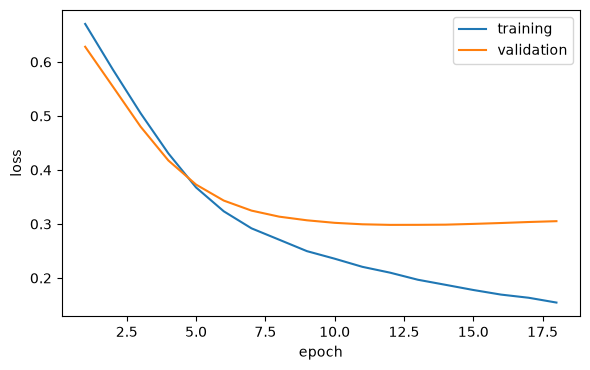

validation accuracy of the best pipeline: 0.871


In [36]:
best_net = search.best_estimator_["net"]
h = best_net.history
epochs = np.arange(1, len(h) + 1)

plt.figure(figsize=(6, 3.8))
plt.plot(epochs, h[:, "train_loss"], label="training")
plt.plot(epochs, h[:, "valid_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.tight_layout()
plt.show()

print("validation accuracy of the best pipeline:", round(search.score(text_valid, y_valid), 3))

---
# Exercises

- **The input.** Change the number of SVD components to 50 and to 600. How do the best validation loss,
  the best epoch and the training time change?
- **Two outputs.** Replace the single logit with two outputs and `NeuralNetClassifier`, which uses
  `CrossEntropyLoss` with integer labels. Is it the same model?
- **Activations.** Change `nn.ReLU()` to `nn.Tanh()` and to `nn.Sigmoid()`, in a network with three
  hidden layers. What happens to the first epochs?
- **A scheduler.** Replace `ReduceLROnPlateau` with a decay that does not look at the validation loss,
  for example `StepLR` or `CosineAnnealingLR`.
- **A search.** A skorch network can be used inside `RandomizedSearchCV`. Search over the learning rate,
  the dropout and the width with a budget of 10 configurations. Does the best configuration
  beat the one we chose by hand?
- **Few examples.** Train on 500 reviews only. What changes in the learning curves?